# Analysing the Rice-Leaf Model Outputs in R


## 0 : CONFIG and setup

In [1]:
DATA_MODE   <- "zip"
ZIP_PATH    <- "/content/CSST102_outputs_for_R.zip"
IN_DIR      <- "/content/py_outputs"
GDRIVE_URL  <- ""
SEED        <- 42
N_BOOT      <- 1000
ALPHA       <- 0.05

DATASET_SOURCE <- list(name = "FILL IN", author = "FILL IN", url = "FILL IN",
                       licence = "FILL IN", restrictions = "FILL IN (e.g. non-commercial, citation required)")

OUT_DIR <- "/content/outputs_R"; FIG_DIR <- file.path(OUT_DIR, "figures")
dir.create(FIG_DIR, recursive = TRUE, showWarnings = FALSE)

In [2]:
os_info  <- readLines("/etc/os-release")
codename <- sub("VERSION_CODENAME=", "", grep("^VERSION_CODENAME=", os_info, value = TRUE))
if (length(codename) == 1 && nzchar(codename)) {
  options(repos = c(CRAN = paste0("https://packagemanager.posit.co/cran/__linux__/", codename, "/latest")))
  options(HTTPUserAgent = sprintf("R/%s R (%s)", getRversion(),
          paste(getRversion(), R.version["platform"], R.version["arch"], R.version["os"])))
} else options(repos = c(CRAN = "https://cloud.r-project.org"))

for (pkg in c("tidyverse", "jsonlite")) if (!requireNamespace(pkg, quietly = TRUE)) install.packages(pkg, quiet = TRUE)
suppressPackageStartupMessages(library(tidyverse))
theme_set(theme_minimal(base_size = 12))
set.seed(SEED)
cat("R", as.character(getRversion()), "| tidyverse", as.character(packageVersion("tidyverse")), "\n")

R 4.6.1 | tidyverse 2.0.0 


---
# WEEK 2 : Data Collection, Importation, and Exploration Using R

## 2.1 Import the files exported by the Python notebook

In [4]:
if (DATA_MODE == "zip") {
  stopifnot("ZIP not found - drag CSST102_outputs_for_R.zip into the Files panel" = file.exists(ZIP_PATH))
  dir.create(IN_DIR, showWarnings = FALSE, recursive = TRUE)
  system(sprintf("unzip -q -o '%s' -d '%s'", ZIP_PATH, IN_DIR))
} else if (DATA_MODE == "gdown") {
  system("pip install -q gdown"); system(sprintf("gdown --fuzzy '%s' -O /content/py_outputs.zip", GDRIVE_URL))
  dir.create(IN_DIR, showWarnings = FALSE, recursive = TRUE); system(sprintf("unzip -q -o /content/py_outputs.zip -d '%s'", IN_DIR))
}
needed <- c("images_inventory.csv", "predictions_all.csv", "run_metrics.csv", "training_history.csv", "robustness.csv",
            "class_names.csv", "advice_kb.csv", "manifest.json")
stopifnot("Missing exported files - re-run Python section 7.8" = all(file.exists(file.path(IN_DIR, needed))))

read_in    <- function(f) read_csv(file.path(IN_DIR, f), show_col_types = FALSE)
inv        <- read_in("images_inventory.csv")
pred       <- read_in("predictions_all.csv")
run_met    <- read_in("run_metrics.csv")
train_hist <- read_in("training_history.csv")
rob        <- read_in("robustness.csv")
class_tbl  <- read_in("class_names.csv")
kb         <- read_in("advice_kb.csv")
manifest   <- jsonlite::fromJSON(file.path(IN_DIR, "manifest.json"))

cat("Imported tables (rows x cols):\n")
for (nm in c("inv", "pred", "run_met", "train_hist", "rob", "class_tbl", "kb")) cat(sprintf("  %-10s %6d x %d\n", nm, nrow(get(nm)), ncol(get(nm))))
cat("\nRuns found:", paste(unique(pred$run), collapse = ", "), "\nFinal run chosen in Python:", manifest$final_run, "\n")

Imported tables (rows x cols):
  inv          8200 x 19
  pred         4920 x 19
  run_met         4 x 15
  train_hist      8 x 8
  rob             5 x 4
  class_tbl      10 x 2
  kb             10 x 6

Runs found: v4_baseline_frozen, v3_frozen 
Final run chosen in Python: v4_baseline_frozen 


## 2.2 Data dictionary

In [5]:
data_dictionary <- tribble(
  ~table,                   ~variable,                                                                  ~type,         ~description,
  "images_inventory",       "image_id",                                                                 "integer",     "Unique id of an image (row id in the Python table)",
  "images_inventory",       "file_name, class_name",                                                    "character",   "Image file name and its class folder (the true label)",
  "images_inventory",       "label",                                                                    "integer",     "Class index 0-7 (alphabetical order of class_name)",
  "images_inventory",       "split",                                                                    "character",   "train / val / test assignment made in Python (stratified 70/15/15, seed 42)",
  "images_inventory",       "width, height, aspect_ratio",                                              "numeric",     "Image size in pixels and width/height",
  "images_inventory",       "size_kb, md5, mode",                                                       "mixed",       "File size (KB), MD5 fingerprint, colour mode",
  "images_inventory",       "mean_r, mean_g, mean_b",                                                   "numeric",     "Average colour channels of a 64x64 thumbnail (0-1)",
  "images_inventory",       "brightness, contrast, saturation",                                         "numeric",     "Mean / SD of luminance; mean colour saturation (0-1)",
  "images_inventory",       "green_ratio, non_green_frac",                                              "numeric",     "G/(R+G+B); share of pixels where green <= red",
  "predictions_all",        "run",                                                                      "character",   "Model run: v4_baseline_frozen, v3_frozen, v4_finetune_basic, v4_finetune_strong",
  "predictions_all",        "split",                                                                    "character",   "val or test (train predictions are not exported)",
  "predictions_all",        "label, class_name",                                                        "mixed",       "True class index and name",
  "predictions_all",        "pred_label, pred_class",                                                   "mixed",       "Predicted class index and name (argmax of the probabilities)",
  "predictions_all",        "confidence",                                                               "numeric",     "Highest predicted probability (0-1)",
  "predictions_all",        "correct",                                                                  "integer",     "1 if prediction == truth else 0",
  "predictions_all",        "p_<class name>",                                                           "numeric",     "Predicted probability for each of the 8 classes (rows sum to 1)",
  "run_metrics",            "run, split, model, setup",                                                 "character",   "Which run / split / architecture / training setup the metrics belong to",
  "run_metrics",            "accuracy ... roc_auc_ovr",                                                 "numeric",     "Metrics computed by Python (accuracy, balanced_acc, macro_f1, top3_acc, log_loss ...)",
  "run_metrics",            "params_M, latency_ms",                                                     "numeric",     "Model size (millions of parameters); inference time per image",
  "training_history",       "run, epoch, train_loss, train_acc, val_loss, val_acc, val_macro_f1, secs", "numeric",     "One row per training epoch",
  "robustness",             "condition, macro_F1, accuracy, drop_vs_clean",                             "mixed",       "Final model on test images made darker/brighter/blurry/low-res",
  "manifest.json",          "n_*, final_run, conf_threshold, reported_test_metrics",                    "mixed",       "Counts and numbers that R must be able to reproduce"
)
print(data_dictionary, n = Inf, width = Inf)
write_csv(data_dictionary, file.path(OUT_DIR, "data_dictionary.csv"))

# A tibble: 22 × 4
   table           
   <chr>           
 1 images_inventory
 2 images_inventory
 3 images_inventory
 4 images_inventory
 5 images_inventory
 6 images_inventory
 7 images_inventory
 8 images_inventory
 9 images_inventory
10 predictions_all 
11 predictions_all 
12 predictions_all 
13 predictions_all 
14 predictions_all 
15 predictions_all 
16 predictions_all 
17 run_metrics     
18 run_metrics     
19 run_metrics     
20 training_history
21 robustness      
22 manifest.json   
   variable                                                                
   <chr>                                                                   
 1 image_id                                                                
 2 file_name, class_name                                                   
 3 label                                                                   
 4 split                                                                   
 5 width, height, aspect_ratio               

## 2.3 Data types, missing values, duplicates, and consistency with the Python run

In [8]:
cat("---- structure of the two main tables ----\n"); glimpse(inv); glimpse(pred %>% select(1:12))

na_tbl <- tibble(table = c("inv", "pred", "run_met", "train_hist", "rob"),
                 n_missing_cells = c(sum(is.na(inv)), sum(is.na(pred)), sum(is.na(run_met)), sum(is.na(train_hist)), sum(is.na(rob))))
cat("\n---- missing values ----\n"); print(na_tbl)
cat("Columns with missing values in run_met:", paste(names(which(colSums(is.na(run_met)) > 0)), collapse = ", "), "\n")

prob_cols <- paste0("p_", class_tbl$class_name)
dup_img  <- sum(duplicated(inv$image_id)); dup_md5 <- sum(duplicated(inv$md5))
dup_pred <- sum(duplicated(pred[c("run", "split", "image_id")]))
prob_sum_ok <- all(abs(rowSums(pred[prob_cols]) - 1) < 1e-3)

import_checks <- c(
  "image_id is unique in the inventory"                          = dup_img == 0,
  "no duplicate images (same md5) after Python cleaning"          = dup_md5 == 0,
  "one prediction per image x run x split"                        = dup_pred == 0,
  "inventory rows == manifest 'n_after_cleaning'"                 = nrow(inv) == manifest$n_after_cleaning,
  "train/val/test sizes match the manifest"                       = all(table(inv$split)[c("train", "val", "test")] == c(manifest$n_train, manifest$n_val, manifest$n_test)),
  "every run has n_val + n_test prediction rows"                  = all(count(pred, run)$n == manifest$n_val + manifest$n_test),
  "predicted probabilities sum to 1"                              = prob_sum_ok,
  "all 8 classes present"                                         = nrow(class_tbl) == 10 && all(sort(unique(inv$label)) == class_tbl$label),
  "every predicted image_id exists in the inventory"              = all(pred$image_id %in% inv$image_id)
)
print(tibble(check = names(import_checks), passed = unname(import_checks)), n = Inf, width = Inf)
stopifnot("Import check failed - the exported files are inconsistent" = all(import_checks))
cat("imported data dimensions match the Python manifest\n")

---- structure of the two main tables ----
Rows: 8,200
Columns: 19
$ class_name     <chr> "Healthy", "Healthy", "Healthy", "Healthy", "Healthy", …
$ label          <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0…
$ width          <dbl> 1600, 1200, 1600, 2160, 4000, 1600, 1600, 1600, 1600, 1…
$ height         <dbl> 1200, 949, 1600, 3840, 3000, 1200, 1600, 1600, 1200, 16…
$ size_kb        <dbl> 854.6416, 214.3232, 184.5127, 670.2012, 1119.2129, 167.…
$ md5            <chr> "99d7536b566a38ea13eb1f77483951ad", "b523b7010586d02248…
$ mode           <chr> "RGB", "RGB", "RGB", "RGB", "RGB", "RGB", "RGB", "RGB",…
$ image_id       <dbl> 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 1…
$ split          <chr> "train", "test", "train", "train", "test", "train", "tr…
$ file_name      <chr> "Healthy_rice_leaf (52).jpg", "Healthy_rice_leaf  (34).…
$ mean_r         <dbl> 0.4383062, 0.4459511, 0.7122013, 0.3290058, 0.4205595, …
$ mean_g         <dbl> 0.6859701, 0.6847819, 0.722171

## 2.4 Data source and data-use restrictions

In [9]:
source_record <- tibble(field = c(names(DATASET_SOURCE), "python_note_on_source", "model", "software"),
                        value = c(unlist(DATASET_SOURCE), manifest$dataset_source_note, paste(manifest$model_name, "(timm", manifest$timm, ")"),
                                  paste("PyTorch", manifest$torch)))
print(source_record, width = Inf)
if (any(grepl("FILL IN", source_record$value))) cat("\n Fill in DATASET_SOURCE (CONFIG cell) and DATASET_SOURCE_NOTE (Python CONFIG) before submitting.\n")
cat("\nData-use note: the images belong to the original dataset's authors - follow their licence. This notebook only uses model outputs and thumbnails-derived colour statistics.\n")
write_csv(source_record, file.path(OUT_DIR, "data_source_record.csv"))

issues <- tribble(
  ~issue,                                                   ~finding,                                                                                          ~action,
  "Predictions exist only for val and test",                "train predictions are not exported",                                                              "over-fitting is judged from the training curves instead",
  "Test set is small per class",                            sprintf("smallest test class has %d images", min(count(filter(inv, split == "test"), label)$n)),   "report confidence intervals, avoid over-reading single-class numbers",
  "Colour features are from 64x64 thumbnails",              "coarse",                                                                                          "used only to see whether image properties relate to errors",
  "Augmented/ folder was not used for evaluation",          sprintf("%d augmented files existed in Python", manifest$n_augmented_files),                       "avoids leakage; nothing to analyse here"
)
print(issues, width = Inf); write_csv(issues, file.path(OUT_DIR, "data_quality_issues.csv"))

# A tibble: 8 × 2
  field                 value                                                  
  <chr>                 <chr>                                                  
1 name                  "FILL IN"                                              
2 author                "FILL IN"                                              
3 url                   "FILL IN"                                              
4 licence               "FILL IN"                                              
5 restrictions          "FILL IN (e.g. non-commercial, citation required)"     
6 python_note_on_source ""                                                     
7 model                 "mobilenetv4_conv_medium.e500_r256_in1k (timm 1.0.31 )"
8 software              "PyTorch 2.14.1+cpu"                                   

 Fill in DATASET_SOURCE (CONFIG cell) and DATASET_SOURCE_NOTE (Python CONFIG) before submitting.

Data-use note: the images belong to the original dataset's authors - follow their l

### Week 2 quick-quality check
- [x] Imported dimensions match the Python manifest (9 automatic checks above)
- [x] Variable names and meanings documented → `data_dictionary.csv`
- [x] Data-quality issues recorded → `data_quality_issues.csv`

# WEEK 3 : Data Cleaning, Descriptive Statistics, and Visualization

| Deliverable | Where |
|---|---|
| Clean and transform data as needed | §3.1 |
| Calculate suitable summary statistics | §3.2 |
| Create at least three meaningful visualizations | §3.3 (seven charts) |
| Save the R code and preliminary outputs | §3.4 |

## 3.1 Cleaning and transformation

In [10]:
FINAL      <- manifest$final_run
class_lvls <- class_tbl$class_name[order(class_tbl$label)]
run_lvls   <- unique(pred$run)

clean_log <- tibble(step = "start: predictions_all rows", rows = nrow(pred))
pred2 <- pred %>%
  mutate(run = factor(run, levels = run_lvls), split = factor(split, levels = c("val", "test")),
         class_name = factor(class_name, levels = class_lvls), pred_class = factor(pred_class, levels = class_lvls),
         correct = as.logical(correct))
clean_log <- bind_rows(clean_log, tibble(step = "convert run/split/class to factors, correct to logical", rows = nrow(pred2)))

P <- as.matrix(pred2[prob_cols])
pred2 <- pred2 %>% mutate(pred_label_r = max.col(P, ties.method = "first") - 1L)
stopifnot("Python pred_label != argmax(probabilities)" = all(pred2$pred_label_r == pred2$pred_label),
          "'correct' column inconsistent"             = all(pred2$correct == (pred2$label == pred2$pred_label)))
clean_log <- bind_rows(clean_log, tibble(step = "verified pred_label == argmax(p) and correct == (label == pred)", rows = nrow(pred2)))

pj <- pred2 %>% left_join(inv %>% select(image_id, split_assigned = split, width, height, aspect_ratio, size_kb,
                                         mean_r, mean_g, mean_b, brightness, contrast, saturation, green_ratio, non_green_frac), by = "image_id") %>%
  mutate(confidence_bin = cut(confidence, breaks = seq(0, 1, 0.1), include.lowest = TRUE),
         error = !correct)
stopifnot("split in predictions != split in inventory" = all(as.character(pj$split) == pj$split_assigned))
clean_log <- bind_rows(clean_log, tibble(step = "joined image properties; split labels agree with inventory", rows = nrow(pj)))
inv <- inv %>% mutate(class_name = factor(class_name, levels = class_lvls), split = factor(split, levels = c("train", "val", "test")))

FINAL_TEST <- pj %>% filter(run == FINAL, split == "test")
print(clean_log, width = Inf); write_csv(clean_log, file.path(OUT_DIR, "cleaning_log.csv"))
cat("\nFinal-model test set:", nrow(FINAL_TEST), "images,", sum(FINAL_TEST$error), "errors\n")

# A tibble: 4 × 2
  step                                                             rows
  <chr>                                                           <int>
1 start: predictions_all rows                                      4920
2 convert run/split/class to factors, correct to logical           4920
3 verified pred_label == argmax(p) and correct == (label == pred)  4920
4 joined image properties; split labels agree with inventory       4920

Final-model test set: 1230 images, 315 errors


## 3.2 Summary statistics
I compute precision / recall / F1 **myself in R from the raw predictions** (not copied from Python) — these helper functions are reused for testing and validation.

In [11]:
per_class <- function(truth, predl) {
  map_dfr(class_tbl$label, function(l) {
    tp <- sum(truth == l & predl == l); fp <- sum(truth != l & predl == l); fn <- sum(truth == l & predl != l)
    prec <- ifelse(tp + fp == 0, 0, tp / (tp + fp)); rec <- ifelse(tp + fn == 0, 0, tp / (tp + fn))
    tibble(label = l, support = tp + fn, tp = tp, precision = prec, recall = rec, f1 = ifelse(prec + rec == 0, 0, 2 * prec * rec / (prec + rec)))
  }) %>% left_join(class_tbl, by = "label")
}
macro_f1 <- function(truth, predl) mean(per_class(truth, predl)$f1)
accuracy <- function(truth, predl) mean(truth == predl)
top3_acc <- function(d) { M <- as.matrix(d[prob_cols]); mean(map_lgl(seq_len(nrow(d)), function(i) (d$label[i] + 1) %in% order(M[i, ], decreasing = TRUE)[1:3])) }

run_summary <- pj %>% group_by(run, split) %>%
  summarise(n = n(), accuracy = accuracy(label, pred_label), macro_f1 = macro_f1(label, pred_label),
            mean_conf = mean(confidence), .groups = "drop")
cat("---- performance of every run (computed in R) ----\n"); print(run_summary %>% mutate(across(where(is.numeric), ~ round(.x, 4))), n = Inf, width = Inf)

pc_final <- per_class(FINAL_TEST$label, FINAL_TEST$pred_label)
cat("\n---- per-class results, final model, test set ----\n"); print(pc_final %>% select(class_name, support, precision, recall, f1) %>% mutate(across(where(is.numeric), ~ round(.x, 3))), width = Inf)

split_counts <- inv %>% count(split, class_name) %>% pivot_wider(names_from = split, values_from = n, values_fill = 0)
cat("\n---- images per class and split ----\n"); print(split_counts, width = Inf)

conf_summary <- FINAL_TEST %>% group_by(correct) %>%
  summarise(n = n(), mean = mean(confidence), sd = sd(confidence), median = median(confidence), iqr = IQR(confidence), min = min(confidence), .groups = "drop")
cat("\n---- confidence when the model is right vs wrong (final, test) ----\n"); print(conf_summary %>% mutate(across(where(is.numeric), ~ round(.x, 3))), width = Inf)

prop_summary <- inv %>% group_by(class_name) %>%
  summarise(n = n(), across(c(brightness, contrast, saturation, green_ratio), list(mean = mean, sd = sd), .names = "{.col}_{.fn}"), .groups = "drop")
cat("\n---- image colour properties by class ----\n"); print(prop_summary %>% mutate(across(where(is.numeric), ~ round(.x, 3))), width = Inf)
write_csv(run_summary, file.path(OUT_DIR, "summary_runs.csv")); write_csv(pc_final, file.path(OUT_DIR, "summary_per_class_final.csv"))
write_csv(prop_summary, file.path(OUT_DIR, "summary_image_properties.csv")); write_csv(split_counts, file.path(OUT_DIR, "summary_split_counts.csv"))

---- performance of every run (computed in R) ----
# A tibble: 4 × 6
  run                split     n accuracy macro_f1 mean_conf
  <fct>              <fct> <dbl>    <dbl>    <dbl>     <dbl>
1 v4_baseline_frozen val    1230    0.743    0.746     0.843
2 v4_baseline_frozen test   1230    0.744    0.748     0.844
3 v3_frozen          val    1230    0.822    0.826     0.848
4 v3_frozen          test   1230    0.809    0.812     0.842

---- per-class results, final model, test set ----
# A tibble: 10 × 5
   class_name            support precision recall    f1
   <chr>                   <dbl>     <dbl>  <dbl> <dbl>
 1 Healthy                   124     0.822  0.782 0.802
 2 bacterial_leaf_blight     143     0.743  0.727 0.735
 3 brown_spot                147     0.73   0.68  0.704
 4 leaf_blast                118     0.667  0.424 0.518
 5 leaf_scald                106     0.784  0.651 0.711
 6 narrow_brown_spot         133     0.594  0.617 0.605
 7 neck_blast                 99     0.97   0.

## 3.3 Visualizations (each has title, axis labels, readable scale)

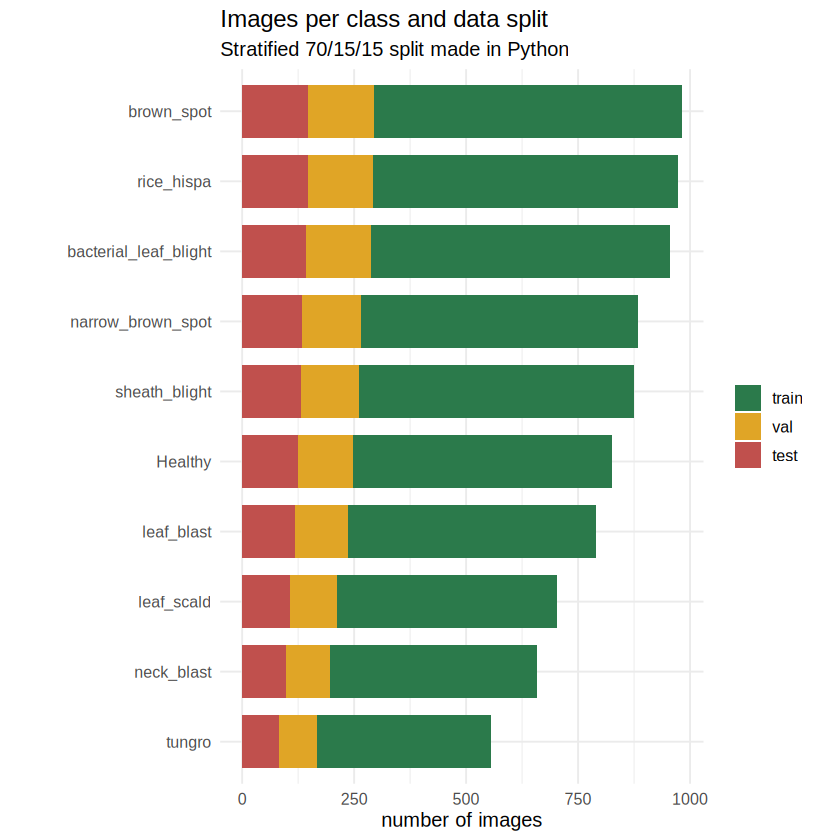

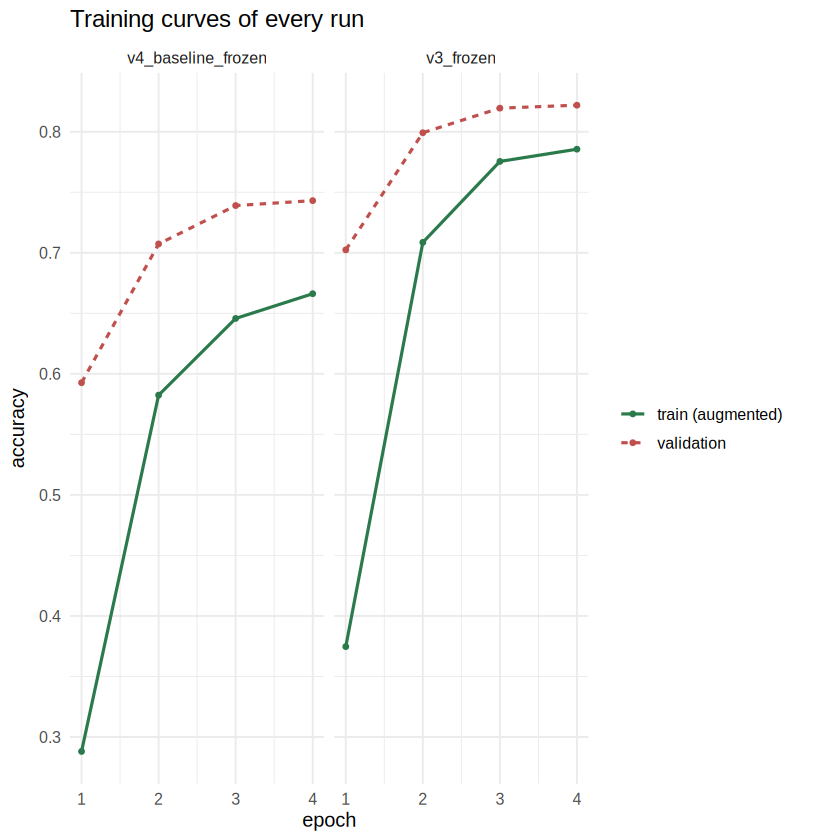

In [12]:
save_plot <- function(p, name, w = 8, h = 5) { ggsave(file.path(FIG_DIR, name), p, width = w, height = h, dpi = 150); print(p) }
PAL <- scale_fill_viridis_d(option = "D", end = 0.9)

p1 <- inv %>% count(split, class_name) %>%
  ggplot(aes(x = n, y = fct_reorder(class_name, n, sum), fill = split)) + geom_col(width = 0.75) +
  scale_fill_manual(values = c(train = "#2b7a4b", val = "#e0a526", test = "#c0504d")) +
  labs(title = "Images per class and data split", subtitle = "Stratified 70/15/15 split made in Python", x = "number of images", y = NULL, fill = NULL)
save_plot(p1, "fig1_split_counts.png")

p2 <- train_hist %>% mutate(run = factor(run, levels = run_lvls)) %>%
  pivot_longer(c(train_acc, val_acc), names_to = "series", values_to = "accuracy") %>%
  ggplot(aes(epoch, accuracy, colour = series, linetype = series)) + geom_line(linewidth = 0.9) + geom_point(size = 1.2) +
  facet_wrap(~ run, ncol = 2) + scale_colour_manual(values = c(train_acc = "#2b7a4b", val_acc = "#c0504d"), labels = c("train (augmented)", "validation")) +
  scale_linetype_discrete(labels = c("train (augmented)", "validation")) +
  labs(title = "Training curves of every run", x = "epoch", y = "accuracy", colour = NULL, linetype = NULL)
save_plot(p2, "fig2_training_curves.png", w = 9, h = 6)

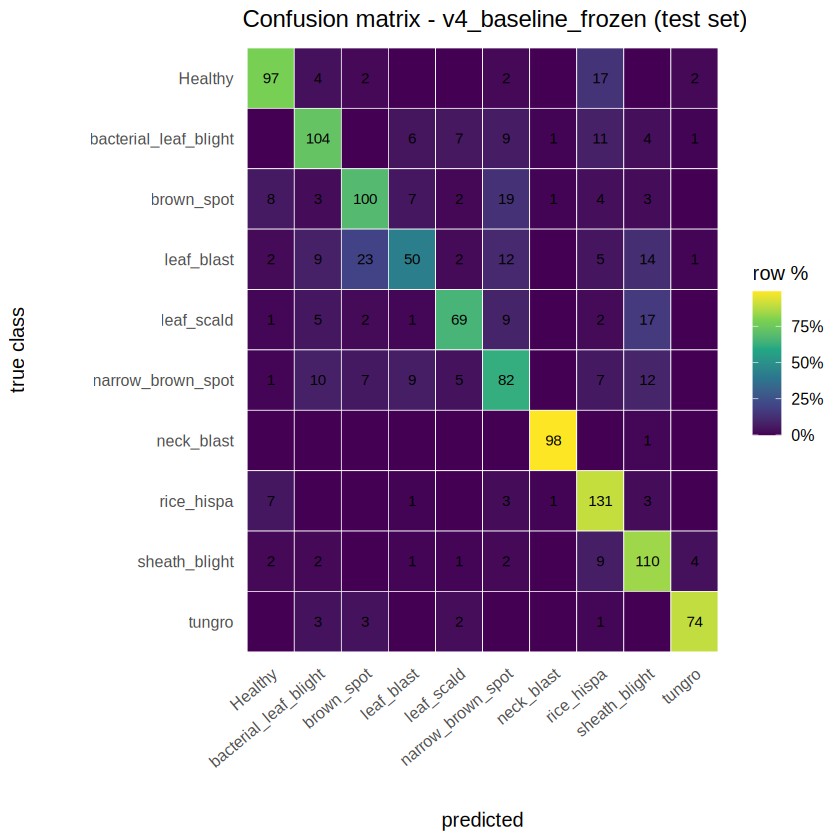

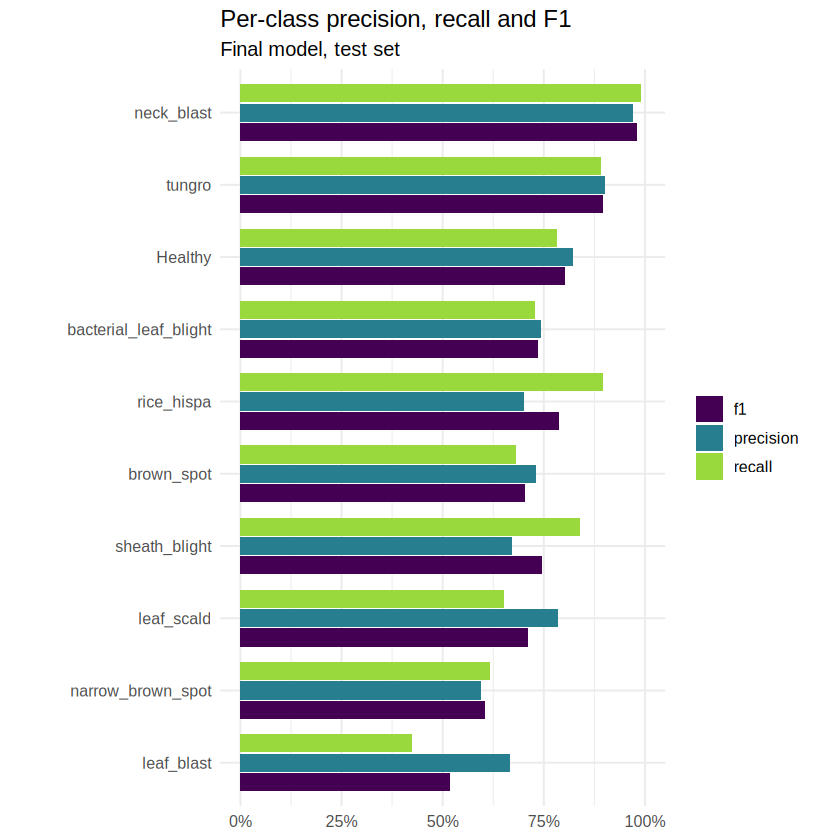

In [13]:
cm_long <- FINAL_TEST %>% count(class_name, pred_class, .drop = FALSE) %>% group_by(class_name) %>% mutate(share = n / sum(n)) %>% ungroup()
p3 <- ggplot(cm_long, aes(pred_class, fct_rev(class_name), fill = share)) + geom_tile(colour = "white") +
  geom_text(aes(label = ifelse(n > 0, n, "")), size = 3.2) + scale_fill_viridis_c(option = "D", labels = scales::percent, name = "row %") +
  labs(title = sprintf("Confusion matrix - %s (test set)", FINAL), x = "predicted", y = "true class") +
  theme(axis.text.x = element_text(angle = 40, hjust = 1), panel.grid = element_blank())
save_plot(p3, "fig3_confusion_matrix.png", w = 8.5, h = 6.5)

p4 <- pc_final %>% pivot_longer(c(precision, recall, f1), names_to = "metric", values_to = "value") %>%
  ggplot(aes(value, fct_reorder(class_name, value, min), fill = metric)) + geom_col(position = position_dodge(width = 0.8), width = 0.75) +
  scale_x_continuous(limits = c(0, 1), labels = scales::percent) + scale_fill_viridis_d(option = "D", end = 0.85) +
  labs(title = "Per-class precision, recall and F1", subtitle = "Final model, test set", x = NULL, y = NULL, fill = NULL)
save_plot(p4, "fig4_per_class_metrics.png", w = 8.5, h = 6)

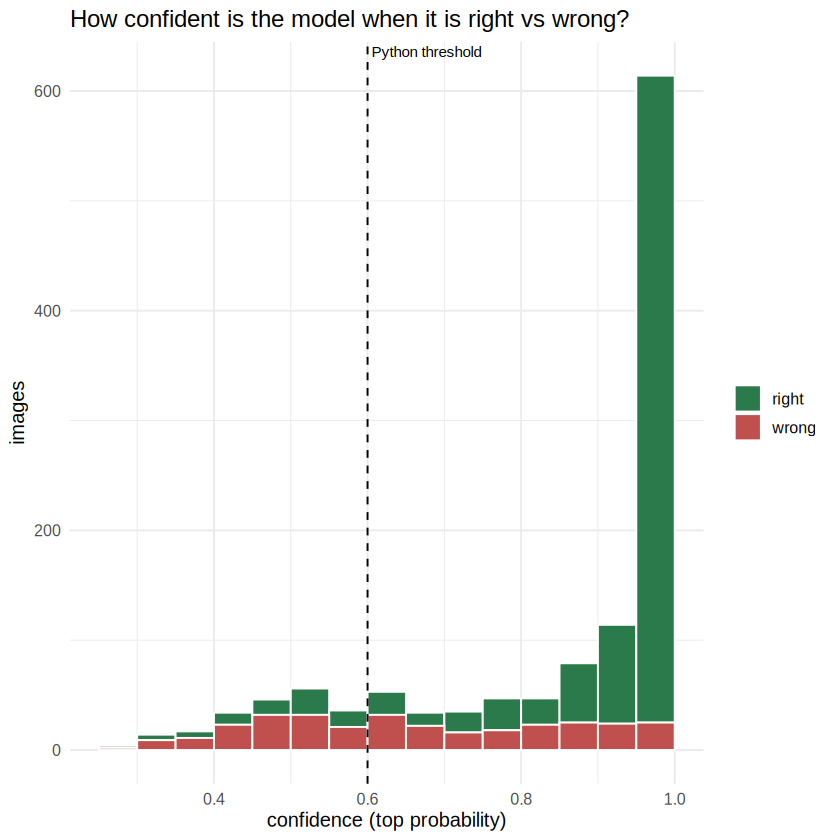

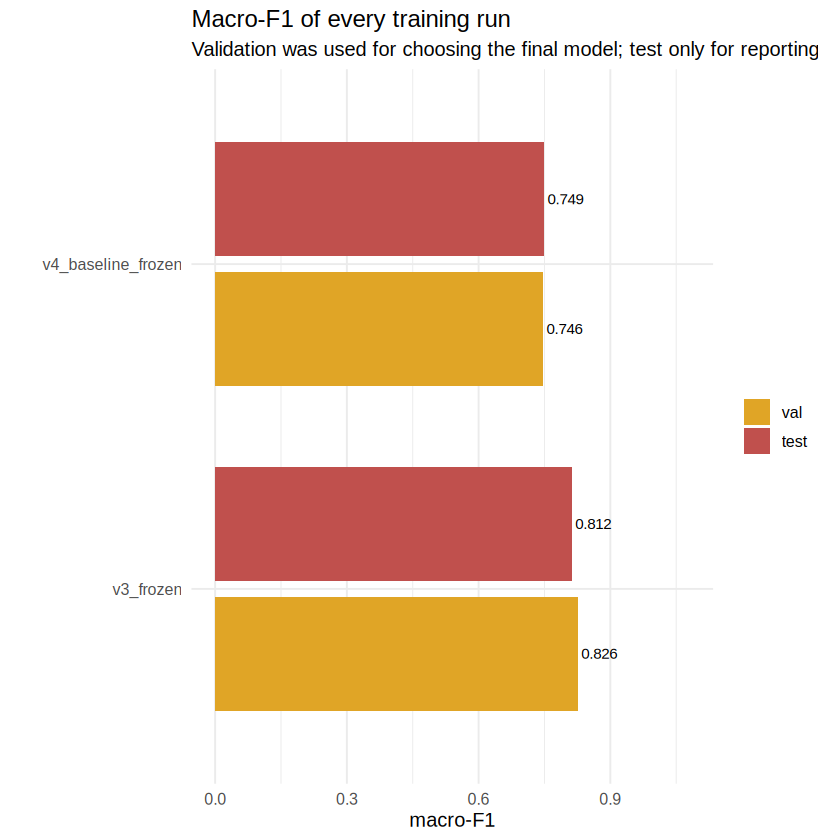

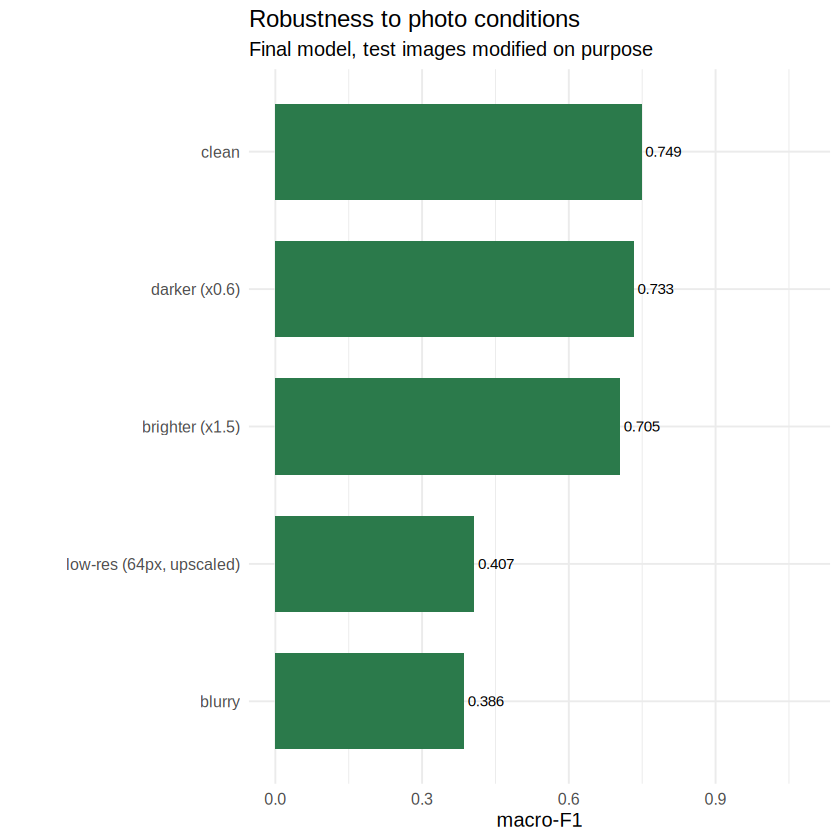

In [14]:
p5 <- ggplot(FINAL_TEST %>% mutate(outcome = ifelse(correct, "right", "wrong")), aes(confidence, fill = outcome)) + geom_histogram(binwidth = 0.05, boundary = 0, position = "stack", colour = "white") +
  geom_vline(xintercept = manifest$conf_threshold, linetype = "dashed") +
  annotate("text", x = manifest$conf_threshold, y = Inf, label = " Python threshold", hjust = 0, vjust = 1.5, size = 3.2) +
  scale_fill_manual(values = c(right = "#2b7a4b", wrong = "#c0504d")) +
  labs(title = "How confident is the model when it is right vs wrong?", x = "confidence (top probability)", y = "images", fill = NULL)
save_plot(p5, "fig5_confidence_hist.png")

p6 <- run_summary %>% ggplot(aes(macro_f1, fct_rev(run), fill = split)) + geom_col(position = position_dodge(width = 0.8), width = 0.7) +
  geom_text(aes(label = sprintf("%.3f", macro_f1)), position = position_dodge(width = 0.8), hjust = -0.1, size = 3.2) +
  scale_x_continuous(limits = c(0, 1.08)) + scale_fill_manual(values = c(val = "#e0a526", test = "#c0504d")) +
  labs(title = "Macro-F1 of every training run", subtitle = "Validation was used for choosing the final model; test only for reporting", x = "macro-F1", y = NULL, fill = NULL)
save_plot(p6, "fig6_model_comparison.png")

p7 <- rob %>% mutate(condition = fct_reorder(condition, macro_F1)) %>%
  ggplot(aes(macro_F1, condition)) + geom_col(fill = "#2b7a4b", width = 0.7) + geom_text(aes(label = sprintf("%.3f", macro_F1)), hjust = -0.1, size = 3.2) +
  scale_x_continuous(limits = c(0, 1.08)) + labs(title = "Robustness to photo conditions", subtitle = "Final model, test images modified on purpose", x = "macro-F1", y = NULL)
save_plot(p7, "fig7_robustness.png", w = 8, h = 4)

## 3.4 Saved outputs
All tables and figures are in `/content/outputs_R/` (`summary_*.csv`, `cleaning_log.csv`, `figures/*.png`).

### Week 3 quick-quality check
- [x] Cleaning steps applied consistently and logged (`cleaning_log.csv`), including consistency checks against Python
- [x] Summary statistics appropriate: per-class precision/recall/F1 for imbalanced classes, median/IQR for confidence
- [x] Seven charts with titles, labels and readable scales

# WEEK 4 : Statistical Analysis and Interpretation of Results

| Deliverable | Where |
|---|---|
| Perform the main statistical analysis | §4.2 – §4.7 |
| Check calculations and visual presentation | §4.8 (full verification in Week 5) |
| Relate findings to the research question | §4.9 |
| Record preliminary interpretations | §4.9 |

## 4.1 Questions and methods
| # | Question | Method | Why |
|---|---|---|---|
| Q1 | How accurate is the final model, with what uncertainty? | Bootstrap 95 % CI (resampling test images) for accuracy & macro-F1; Wilson CI for per-class recall | Test set is finite; a single number hides the noise |
| Q2 | Is the final model *significantly* better than the baselines? | **McNemar exact test** on paired right/wrong outcomes + paired bootstrap CI of the macro-F1 difference | Same test images are scored by both models → paired design |
| Q3 | Are errors spread evenly over classes? | Chi-square test of independence (class × right/wrong, Monte-Carlo p) + Cramér's V | Tests whether some classes are systematically harder |
| Q4 | Do image properties (brightness, colour…) predict mistakes? | Logistic regression of *error* on standardised image properties (odds ratios), Mann–Whitney tests | Looks for shortcuts / photo-quality weaknesses |
| Q5 | Can we trust the confidence? | Reliability table, expected calibration error, Brier score, coverage-vs-accuracy of the threshold | Advice shown to farmers depends on it |
| Q6 | Is there over-fitting? | Train–validation gaps from the training history | Judged from curves (train predictions not exported) |

α = 0.05; with many tests, p-values are Holm-adjusted where they form a family.

In [15]:
fmt_p <- function(p) ifelse(p < 0.001, "< 0.001", sprintf("%.3f", p))
wilson <- function(x, n, conf = 0.95) { z <- qnorm(1 - (1 - conf) / 2); ph <- x / n
  centre <- (ph + z^2 / (2 * n)) / (1 + z^2 / n); half <- z * sqrt(ph * (1 - ph) / n + z^2 / (4 * n^2)) / (1 + z^2 / n)
  tibble(lo = pmax(0, centre - half), hi = pmin(1, centre + half)) }

set.seed(SEED)
n_te <- nrow(FINAL_TEST)
boot <- map_dfr(seq_len(N_BOOT), function(i) { ix <- sample.int(n_te, replace = TRUE)
  tibble(acc = accuracy(FINAL_TEST$label[ix], FINAL_TEST$pred_label[ix]), mf1 = macro_f1(FINAL_TEST$label[ix], FINAL_TEST$pred_label[ix])) })
q1 <- tibble(metric = c("accuracy", "macro-F1"),
             estimate = c(accuracy(FINAL_TEST$label, FINAL_TEST$pred_label), macro_f1(FINAL_TEST$label, FINAL_TEST$pred_label)),
             lo = c(quantile(boot$acc, .025), quantile(boot$mf1, .025)), hi = c(quantile(boot$acc, .975), quantile(boot$mf1, .975)))
cat(sprintf("Final model (%s) on %d test images:\n", FINAL, n_te)); print(q1 %>% mutate(across(where(is.numeric), ~ round(.x, 4))))
pc_ci <- pc_final %>% bind_cols(wilson(.$tp, .$support)) %>% rename(recall_lo = lo, recall_hi = hi)
cat("\nPer-class recall with 95% Wilson interval:\n"); print(pc_ci %>% select(class_name, support, recall, recall_lo, recall_hi) %>% mutate(across(where(is.numeric), ~ round(.x, 3))), width = Inf)
target <- 0.90
cat(sprintf("\nProject target macro-F1 >= %.2f: point estimate %s; lower CI bound %.3f -> %s\n", target, ifelse(q1$estimate[2] >= target, "MET", "NOT met"),
            q1$lo[2], ifelse(q1$lo[2] >= target, "confidently met", "not established with certainty")))
write_csv(q1, file.path(OUT_DIR, "q1_bootstrap_ci.csv")); write_csv(pc_ci, file.path(OUT_DIR, "q1_per_class_recall_ci.csv"))

Final model (v4_baseline_frozen) on 1230 test images:
# A tibble: 2 × 4
  metric   estimate    lo    hi
  <chr>       <dbl> <dbl> <dbl>
1 accuracy    0.744 0.721 0.769
2 macro-F1    0.748 0.724 0.773

Per-class recall with 95% Wilson interval:
# A tibble: 10 × 5
   class_name            support recall recall_lo recall_hi
   <chr>                   <dbl>  <dbl>     <dbl>     <dbl>
 1 Healthy                   124  0.782     0.702     0.846
 2 bacterial_leaf_blight     143  0.727     0.649     0.794
 3 brown_spot                147  0.68      0.601     0.75 
 4 leaf_blast                118  0.424     0.338     0.514
 5 leaf_scald                106  0.651     0.556     0.735
 6 narrow_brown_spot         133  0.617     0.532     0.695
 7 neck_blast                 99  0.99      0.945     0.998
 8 rice_hispa                146  0.897     0.837     0.937
 9 sheath_blight             131  0.84      0.767     0.893
10 tungro                     83  0.892     0.807     0.942

Project target m

In [16]:
test_wide <- pj %>% filter(split == "test") %>% select(image_id, label, run, pred_label, correct) %>%
  pivot_wider(names_from = run, values_from = c(pred_label, correct))

compare_runs <- function(other) {
  a <- test_wide[[paste0("correct_", FINAL)]]; b <- test_wide[[paste0("correct_", other)]]
  n10 <- sum(a & !b); n01 <- sum(!a & b)
  p_ex <- if (n10 + n01 > 0) binom.test(n10, n10 + n01, 0.5)$p.value else 1
  set.seed(SEED)
  d <- replicate(N_BOOT, { ix <- sample.int(nrow(test_wide), replace = TRUE)
    macro_f1(test_wide$label[ix], test_wide[[paste0("pred_label_", FINAL)]][ix]) - macro_f1(test_wide$label[ix], test_wide[[paste0("pred_label_", other)]][ix]) })
  tibble(other_run = other, final_only_right = n10, other_only_right = n01, mcnemar_exact_p = p_ex,
         d_macroF1 = macro_f1(test_wide$label, test_wide[[paste0("pred_label_", FINAL)]]) - macro_f1(test_wide$label, test_wide[[paste0("pred_label_", other)]]),
         d_lo = unname(quantile(d, .025)), d_hi = unname(quantile(d, .975)))
}
others <- setdiff(as.character(run_lvls), FINAL)
q2 <- map_dfr(others, compare_runs) %>% mutate(p_holm = p.adjust(mcnemar_exact_p, "holm"), significant = p_holm < ALPHA)
print(q2 %>% mutate(across(c(d_macroF1, d_lo, d_hi), ~ round(.x, 4)), mcnemar_exact_p = fmt_p(mcnemar_exact_p), p_holm = fmt_p(p_holm)), width = Inf)
write_csv(q2, file.path(OUT_DIR, "q2_model_comparison_tests.csv"))

# A tibble: 1 × 9
  other_run final_only_right other_only_right mcnemar_exact_p d_macroF1    d_lo
  <chr>                <int>            <int> <chr>               <dbl>   <dbl>
1 v3_frozen               67              147 < 0.001           -0.0632 -0.0863
     d_hi p_holm  significant
    <dbl> <chr>   <lgl>      
1 -0.0408 < 0.001 TRUE       


In [17]:
tab_err <- table(FINAL_TEST$class_name, factor(FINAL_TEST$correct, levels = c(TRUE, FALSE), labels = c("right", "wrong")))
print(tab_err)
if (sum(tab_err[, "wrong"]) >= 2) {
  set.seed(SEED); chi_err <- suppressWarnings(chisq.test(tab_err, simulate.p.value = TRUE, B = 5000))
  cv <- sqrt(unname(chi_err$statistic) / (sum(tab_err) * (min(dim(tab_err)) - 1)))
  cat(sprintf("\nchi2 = %.2f, Monte-Carlo p %s, Cramer's V = %.2f\n", chi_err$statistic, fmt_p(chi_err$p.value), cv))
} else { chi_err <- NULL; cv <- NA_real_; cat("\nToo few errors for a chi-square test.\n") }

props <- c("brightness", "contrast", "saturation", "green_ratio", "non_green_frac")
err_dat <- FINAL_TEST %>% mutate(across(all_of(props), ~ as.numeric(scale(.x))), log_size_kb = as.numeric(scale(log(size_kb))), error = as.integer(error))
or_tbl <- NULL
if (sum(err_dat$error) >= 10) {
  fit <- glm(reformulate(c(props, "log_size_kb"), "error"), data = err_dat, family = binomial)
  ci  <- suppressMessages(confint.default(fit))
  or_tbl <- tibble(term = names(coef(fit))[-1], odds_ratio = exp(coef(fit))[-1], lo = exp(ci[-1, 1]), hi = exp(ci[-1, 2]), p = summary(fit)$coefficients[-1, 4]) %>%
    mutate(p_holm = p.adjust(p, "holm"))
  cat("\nLogistic regression: odds of a WRONG prediction per +1 SD of each property\n"); print(or_tbl %>% mutate(across(c(odds_ratio, lo, hi), ~ round(.x, 2)), p = fmt_p(p), p_holm = fmt_p(p_holm)), width = Inf)
  write_csv(or_tbl, file.path(OUT_DIR, "q4_logistic_odds_ratios.csv"))
} else cat("\nFewer than 10 errors on the test set: logistic regression skipped (too unstable); showing Mann-Whitney only.\n")

mw <- map_dfr(props, function(v) { g <- split(FINAL_TEST[[v]], FINAL_TEST$correct)
  if (length(g) < 2 || any(lengths(g) < 2)) return(tibble(property = v, median_wrong = NA_real_, median_right = NA_real_, p = NA_real_))
  tibble(property = v, median_wrong = median(g[["FALSE"]]), median_right = median(g[["TRUE"]]), p = wilcox.test(g[["FALSE"]], g[["TRUE"]], exact = FALSE)$p.value) }) %>%
  mutate(p_holm = p.adjust(p, "holm"))
cat("\nMann-Whitney: image property of wrongly vs correctly classified test images\n"); print(mw %>% mutate(across(where(is.numeric), ~ round(.x, 4))), width = Inf)
write_csv(mw, file.path(OUT_DIR, "q4_mann_whitney.csv"))

                       
                        right wrong
  Healthy                  97    27
  bacterial_leaf_blight   104    39
  brown_spot              100    47
  leaf_blast               50    68
  leaf_scald               69    37
  narrow_brown_spot        82    51
  neck_blast               98     1
  rice_hispa              131    15
  sheath_blight           110    21
  tungro                   74     9

chi2 = 149.19, Monte-Carlo p < 0.001, Cramer's V = 0.35

Logistic regression: odds of a WRONG prediction per +1 SD of each property
# A tibble: 6 × 6
  term           odds_ratio    lo    hi p       p_holm 
  <chr>               <dbl> <dbl> <dbl> <chr>   <chr>  
1 brightness           1.75  1.3   2.36 < 0.001 0.001  
2 contrast             0.97  0.83  1.12 0.648   0.648  
3 saturation           3.89  2.3   6.56 < 0.001 < 0.001
4 green_ratio          0.43  0.27  0.69 < 0.001 0.002  
5 non_green_frac       0.63  0.47  0.84 0.002   0.006  
6 log_size_kb          1.09  0.94  1.

Expected calibration error = 0.102 | multi-class Brier score = 0.365 (0 = perfect)
# A tibble: 8 × 4
  bin           n mean_conf accuracy
  <fct>     <dbl>     <dbl>    <dbl>
1 (0.2,0.3]     4     0.283    0.5  
2 (0.3,0.4]    31     0.358    0.355
3 (0.4,0.5]    80     0.457    0.312
4 (0.5,0.6]    92     0.546    0.424
5 (0.6,0.7]    87     0.645    0.379
6 (0.7,0.8]    82     0.752    0.585
7 (0.8,0.9]   126     0.857    0.619
8 (0.9,1]     728     0.98     0.933

Coverage vs accuracy when low-confidence predictions are rejected:
# A tibble: 14 × 3
   threshold coverage accuracy_kept
       <dbl>    <dbl>         <dbl>
 1      0.3     0.997         0.745
 2      0.35    0.985         0.749
 3      0.4     0.972         0.755
 4      0.45    0.944         0.767
 5      0.5     0.907         0.787
 6      0.55    0.861         0.805
 7      0.6     0.832         0.819
 8      0.65    0.789         0.842
 9      0.7     0.761         0.86 
10      0.75    0.733         0.872
11      0.

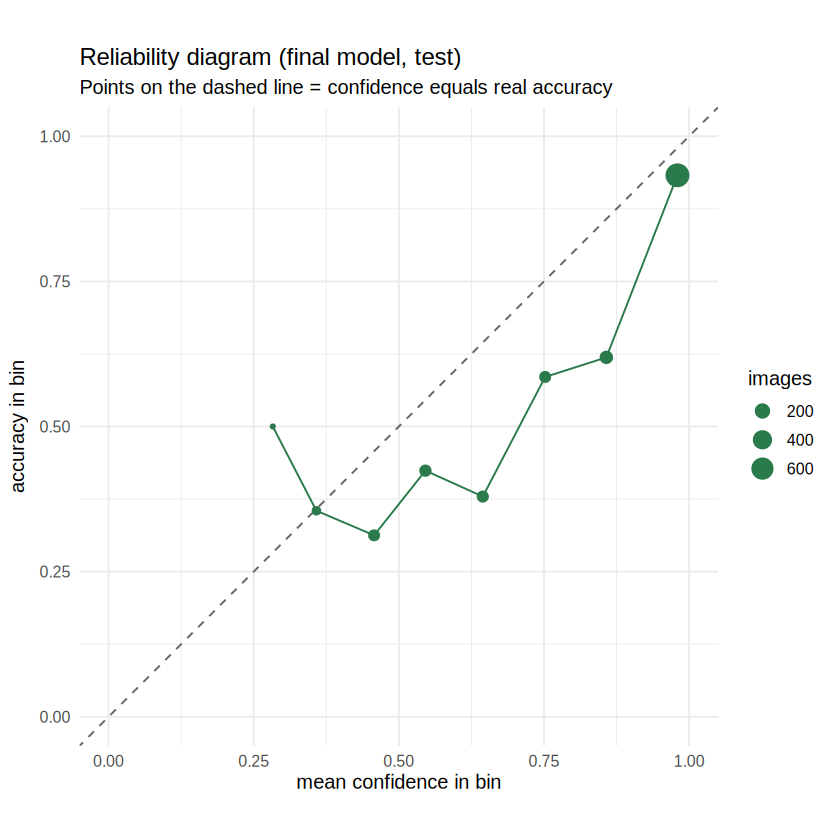

In [18]:
rel <- FINAL_TEST %>% mutate(bin = cut(confidence, seq(0, 1, 0.1), include.lowest = TRUE)) %>% group_by(bin) %>%
  summarise(n = n(), mean_conf = mean(confidence), accuracy = mean(correct), .groups = "drop")
ece <- sum(rel$n / sum(rel$n) * abs(rel$accuracy - rel$mean_conf))
Pm  <- as.matrix(FINAL_TEST[prob_cols]); Y <- outer(FINAL_TEST$label, class_tbl$label, "==") * 1
brier <- mean(rowSums((Pm - Y)^2))
cat(sprintf("Expected calibration error = %.3f | multi-class Brier score = %.3f (0 = perfect)\n", ece, brier)); print(rel %>% mutate(across(where(is.numeric), ~ round(.x, 3))))
p_rel <- ggplot(rel, aes(mean_conf, accuracy)) + geom_abline(linetype = "dashed", colour = "grey40") + geom_line(colour = "#2b7a4b") +
  geom_point(aes(size = n), colour = "#2b7a4b") + coord_equal(xlim = c(0, 1), ylim = c(0, 1)) +
  labs(title = "Reliability diagram (final model, test)", subtitle = "Points on the dashed line = confidence equals real accuracy", x = "mean confidence in bin", y = "accuracy in bin", size = "images")
save_plot(p_rel, "fig8_reliability.png", w = 6, h = 5.5)

thr_tbl <- tibble(threshold = seq(0.3, 0.95, by = 0.05)) %>%
  mutate(coverage = map_dbl(threshold, ~ mean(FINAL_TEST$confidence >= .x)),
         accuracy_kept = map_dbl(threshold, ~ { k <- FINAL_TEST$confidence >= .x; if (any(k)) mean(FINAL_TEST$correct[k]) else NA_real_ }))
cat("\nCoverage vs accuracy when low-confidence predictions are rejected:\n"); print(thr_tbl %>% mutate(across(where(is.numeric), ~ round(.x, 3))), n = Inf)
k <- FINAL_TEST$confidence >= manifest$conf_threshold
cat(sprintf("\nThreshold chosen in Python on validation = %.2f -> on TEST it keeps %.0f%% of images with %.1f%% accuracy (rejected images: %.1f%% accuracy)\n",
            manifest$conf_threshold, 100 * mean(k), 100 * mean(FINAL_TEST$correct[k]), ifelse(any(!k), 100 * mean(FINAL_TEST$correct[!k]), NA)))
conf_mw <- if (length(unique(FINAL_TEST$correct)) == 2) wilcox.test(confidence ~ correct, data = FINAL_TEST, exact = FALSE)$p.value else NA_real_
cat(sprintf("Confidence differs between right and wrong predictions: Mann-Whitney p %s\n", fmt_p(conf_mw)))
write_csv(rel, file.path(OUT_DIR, "q5_reliability.csv")); write_csv(thr_tbl, file.path(OUT_DIR, "q5_threshold_table.csv"))

gap_tbl <- train_hist %>% group_by(run) %>% slice_max(val_macro_f1, n = 1, with_ties = FALSE) %>% ungroup() %>%
  transmute(run, best_epoch = epoch, n_epochs = NA_integer_, train_acc, val_acc, gap = train_acc - val_acc, val_loss)
gap_tbl$n_epochs <- map_int(gap_tbl$run, ~ max(train_hist$epoch[train_hist$run == .x]))
cat("\nTrain - validation accuracy at each run's best epoch (train accuracy is measured WITH augmentation):\n"); print(gap_tbl %>% mutate(across(where(is.numeric), ~ round(.x, 3))), width = Inf)
write_csv(gap_tbl, file.path(OUT_DIR, "q6_overfitting_gaps.csv"))

## 4.8 Check calculations and visual presentation (quick)

In [19]:
chk4 <- c(
  "bootstrap CI contains the point estimate (accuracy)"  = q1$lo[1] <= q1$estimate[1] & q1$estimate[1] <= q1$hi[1],
  "bootstrap CI contains the point estimate (macro-F1)"  = q1$lo[2] <= q1$estimate[2] & q1$estimate[2] <= q1$hi[2],
  "per-class supports sum to test size"                  = sum(pc_final$support) == n_te,
  "all p-values within [0, 1]"                           = all(c(q2$mcnemar_exact_p, mw$p[!is.na(mw$p)]) >= 0 & c(q2$mcnemar_exact_p, mw$p[!is.na(mw$p)]) <= 1),
  "Holm-adjusted p >= raw p"                             = all(q2$p_holm >= q2$mcnemar_exact_p - 1e-12),
  "reliability bins cover all test images"               = sum(rel$n) == n_te,
  "McNemar discordant counts <= test size"               = all(q2$final_only_right + q2$other_only_right <= n_te)
)
print(chk4); stopifnot(all(chk4)); cat("quick checks passed; figures have titles, labelled axes and legends\n")

bootstrap CI contains the point estimate (accuracy).2.5% 
                                                    TRUE 
bootstrap CI contains the point estimate (macro-F1).2.5% 
                                                    TRUE 
                     per-class supports sum to test size 
                                                    TRUE 
                              all p-values within [0, 1] 
                                                    TRUE 
                                Holm-adjusted p >= raw p 
                                                    TRUE 
                  reliability bins cover all test images 
                                                    TRUE 
                  McNemar discordant counts <= test size 
                                                    TRUE 
quick checks passed; figures have titles, labelled axes and legends


In [20]:
worst <- pc_final %>% arrange(f1) %>% slice(1); best <- pc_final %>% arrange(desc(f1)) %>% slice(1)
conf_pairs <- FINAL_TEST %>% filter(error) %>% count(class_name, pred_class, sort = TRUE)
interp <- c(
  sprintf("Accuracy %.1f%% (95%% CI %.1f-%.1f) and macro-F1 %.3f (95%% CI %.3f-%.3f) on %d test images; the 0.90 macro-F1 target is %s.",
          100 * q1$estimate[1], 100 * q1$lo[1], 100 * q1$hi[1], q1$estimate[2], q1$lo[2], q1$hi[2], n_te, ifelse(q1$lo[2] >= target, "confidently met", ifelse(q1$estimate[2] >= target, "met by the point estimate, but the CI reaches below it", "not met"))),
  if (nrow(q2)) sprintf("Versus the other runs, the final model %s (smallest Holm-adjusted McNemar p = %s; macro-F1 difference vs. best other run %+.3f).",
          ifelse(any(q2$significant & q2$d_macroF1 > 0), "is significantly better than at least one run", "is NOT significantly better than any other run on this test set"), fmt_p(min(q2$p_holm)), q2$d_macroF1[which.min(q2$d_macroF1)]) else "Only one run available.",
  sprintf("Best class: %s (F1 %.2f); weakest: %s (F1 %.2f, recall %.0f%%).", best$class_name, best$f1, worst$class_name, worst$f1, 100 * worst$recall),
  if (nrow(conf_pairs)) sprintf("Most frequent confusion: %s mistaken for %s (%dx).", conf_pairs$class_name[1], conf_pairs$pred_class[1], conf_pairs$n[1]) else "No test errors.",
  if (!is.null(chi_err)) sprintf("Errors are %s across classes (chi2 p %s, Cramer's V %.2f).", ifelse(chi_err$p.value < ALPHA, "NOT evenly spread", "consistent with being evenly spread"), fmt_p(chi_err$p.value), cv) else "",
  if (!is.null(or_tbl)) sprintf("Image properties linked to errors after Holm correction: %s.", ifelse(any(or_tbl$p_holm < ALPHA), paste(or_tbl$term[or_tbl$p_holm < ALPHA], collapse = ", "), "none")) else "Too few errors to model which image properties predict them.",
  sprintf("Calibration: ECE %.3f, Brier %.3f. Mean confidence is %.2f when right and %.2f when wrong; at the Python threshold (%.2f) %.0f%% of test images are kept with %.1f%% accuracy.",
          ece, brier, mean(FINAL_TEST$confidence[FINAL_TEST$correct]), ifelse(any(FINAL_TEST$error), mean(FINAL_TEST$confidence[FINAL_TEST$error]), NA), manifest$conf_threshold, 100 * mean(k), 100 * mean(FINAL_TEST$correct[k]))
)
interp <- interp[nzchar(interp)]
cat("PRELIMINARY INTERPRETATIONS (relate to the research question)\n\n"); cat(paste0("  • ", interp), sep = "\n")
cat("\nCaution: the test set is small and comes from the same dataset as training; real field photos will likely be harder. Statistical significance here does not guarantee field performance.\n")
writeLines(interp, file.path(OUT_DIR, "preliminary_interpretations.txt"))

PRELIMINARY INTERPRETATIONS (relate to the research question)

  • Accuracy 74.4% (95% CI 72.1-76.9) and macro-F1 0.749 (95% CI 0.724-0.773) on 1230 test images; the 0.90 macro-F1 target is not met.
  • Versus the other runs, the final model is NOT significantly better than any other run on this test set (smallest Holm-adjusted McNemar p = < 0.001; macro-F1 difference vs. best other run -0.063).
  • Best class: neck_blast (F1 0.98); weakest: leaf_blast (F1 0.52, recall 42%).
  • Most frequent confusion: leaf_blast mistaken for brown_spot (23x).
  • Errors are NOT evenly spread across classes (chi2 p < 0.001, Cramer's V 0.35).
  • Image properties linked to errors after Holm correction: brightness, saturation, green_ratio, non_green_frac.
  • Calibration: ECE 0.102, Brier 0.365. Mean confidence is 0.91 when right and 0.67 when wrong; at the Python threshold (0.60) 83% of test images are kept with 81.9% accuracy.

Caution: the test set is small and comes from the same dataset as training

# WEEK 5 : Results Validation and Analytical Improvement



## 5.1 Verification — do R's independent calculations reproduce what Python reported?

In [21]:
all_eq <- function(a, b, tol = 1e-6) isTRUE(all.equal(as.numeric(a), as.numeric(b), tolerance = tol, check.attributes = FALSE))
rep_tab <- map_dfr(names(manifest$reported_test_metrics), function(r) {
  d <- pj %>% filter(run == r, split == "test"); m <- manifest$reported_test_metrics[[r]]
  tibble(run = r, metric = c("accuracy", "macro_f1", "top3_acc"),
         python = c(m$accuracy, m$macro_f1, m$top3_acc), r_value = c(accuracy(d$label, d$pred_label), macro_f1(d$label, d$pred_label), top3_acc(d)))
}) %>% mutate(abs_diff = abs(python - r_value), match = abs_diff < 1e-6)
print(rep_tab %>% mutate(across(where(is.numeric), ~ signif(.x, 5))), n = Inf, width = Inf)

cm_f   <- table(factor(FINAL_TEST$label, class_tbl$label), factor(FINAL_TEST$pred_label, class_tbl$label))
mf1_alt <- mean(2 * diag(cm_f) / (rowSums(cm_f) + colSums(cm_f)))
w1 <- others[1]
a <- test_wide[[paste0("correct_", FINAL)]]; b <- test_wide[[paste0("correct_", w1)]]
mc_stat_hand <- (abs(sum(a & !b) - sum(!a & b)) - 1)^2 / max(sum(a & !b) + sum(!a & b), 1)
mc_stat_r    <- unname(suppressWarnings(mcnemar.test(table(factor(a, c(TRUE, FALSE)), factor(b, c(TRUE, FALSE))))$statistic))
set.seed(SEED); boot2 <- map_dbl(seq_len(N_BOOT), function(i) { ix <- sample.int(n_te, replace = TRUE); accuracy(FINAL_TEST$label[ix], FINAL_TEST$pred_label[ix]) })

checks <- tibble(
  check  = c("Python-reported accuracy / macro-F1 / top-3 reproduced from raw predictions (all runs)", "macro-F1 via two formulas (precision/recall vs 2TP/(support+predicted))",
             "confusion matrix sums to the test size", "McNemar chi2: by hand == mcnemar.test", "bootstrap is reproducible with the same seed",
             "final run in manifest == best validation macro-F1 among the v4 runs (selection used validation only)", "threshold reported in manifest lies in (0, 1)"),
  passed = c(all(rep_tab$match), all_eq(mf1_alt, macro_f1(FINAL_TEST$label, FINAL_TEST$pred_label)), sum(cm_f) == n_te, all_eq(mc_stat_hand, mc_stat_r, 1e-6),
             all_eq(boot2, boot$acc), FINAL == (run_summary %>% filter(split == "val", startsWith(as.character(run), "v4_")) %>% slice_max(macro_f1, n = 1, with_ties = FALSE) %>% pull(run) %>% as.character()),
             manifest$conf_threshold > 0 && manifest$conf_threshold < 1))
print(checks, width = Inf); write_csv(checks, file.path(OUT_DIR, "verification_checks.csv")); write_csv(rep_tab, file.path(OUT_DIR, "verification_python_vs_r.csv"))
stopifnot("A verification check FAILED - see table above" = all(checks$passed))
cat("\n✅ all", nrow(checks), "verification checks passed: R reproduces the Python results independently\n")

# A tibble: 6 × 6
  run                metric   python r_value abs_diff match
  <chr>              <chr>     <dbl>   <dbl>    <dbl> <lgl>
1 v4_baseline_frozen accuracy  0.744   0.744 0        TRUE 
2 v4_baseline_frozen macro_f1  0.748   0.748 1.11e-16 TRUE 
3 v4_baseline_frozen top3_acc  0.930   0.930 0        TRUE 
4 v3_frozen          accuracy  0.809   0.809 0        TRUE 
5 v3_frozen          macro_f1  0.812   0.812 1.11e-16 TRUE 
6 v3_frozen          top3_acc  0.961   0.961 0        TRUE 
# A tibble: 7 × 2
  check                                                                         
  <chr>                                                                         
1 Python-reported accuracy / macro-F1 / top-3 reproduced from raw predictions (…
2 macro-F1 via two formulas (precision/recall vs 2TP/(support+predicted))       
3 confusion matrix sums to the test size                                        
4 McNemar chi2: by hand == mcnemar.test                                        

## 5.2 Is the conclusion stable? (validation vs test, per-class agreement, resampling)

In [22]:
gen <- run_summary %>% select(run, split, accuracy, macro_f1) %>% pivot_wider(names_from = split, values_from = c(accuracy, macro_f1)) %>%
  mutate(gap_macro_f1 = macro_f1_val - macro_f1_test)
cat("Validation vs test performance (a big gap would mean the model was tuned to validation):\n"); print(gen %>% mutate(across(where(is.numeric), ~ round(.x, 4))), width = Inf)

pc_val <- per_class((pj %>% filter(run == FINAL, split == "val"))$label, (pj %>% filter(run == FINAL, split == "val"))$pred_label) %>% select(class_name, recall_val = recall)
pc_cmp <- pc_final %>% select(class_name, recall_test = recall, support) %>% left_join(pc_val, by = "class_name")
cat(sprintf("\nSpearman correlation of per-class recall, validation vs test: %.2f\n", cor(pc_cmp$recall_val, pc_cmp$recall_test, method = "spearman")))
print(pc_cmp %>% mutate(across(where(is.numeric), ~ round(.x, 3))), width = Inf)

set.seed(SEED); sub_stab <- map_dfr(1:20, function(i) { ix <- sample.int(n_te, round(0.8 * n_te))
  tibble(acc = accuracy(FINAL_TEST$label[ix], FINAL_TEST$pred_label[ix]), mf1 = macro_f1(FINAL_TEST$label[ix], FINAL_TEST$pred_label[ix])) })
sens <- tibble(scenario = c("all test images", "20 random 80% subsets (range)"),
               accuracy = c(sprintf("%.3f", q1$estimate[1]), sprintf("%.3f - %.3f", min(sub_stab$acc), max(sub_stab$acc))),
               macro_f1 = c(sprintf("%.3f", q1$estimate[2]), sprintf("%.3f - %.3f", min(sub_stab$mf1), max(sub_stab$mf1))))
print(sens, width = Inf); write_csv(sens, file.path(OUT_DIR, "sensitivity_checks.csv")); write_csv(gen, file.path(OUT_DIR, "val_vs_test.csv"))

Validation vs test performance (a big gap would mean the model was tuned to validation):
# A tibble: 2 × 6
  run                accuracy_val accuracy_test macro_f1_val macro_f1_test
  <fct>                     <dbl>         <dbl>        <dbl>         <dbl>
1 v4_baseline_frozen        0.743         0.744        0.746         0.748
2 v3_frozen                 0.822         0.809        0.826         0.812
  gap_macro_f1
         <dbl>
1      -0.0022
2       0.014 

Spearman correlation of per-class recall, validation vs test: 0.95
# A tibble: 10 × 4
   class_name            recall_test support recall_val
   <chr>                       <dbl>   <dbl>      <dbl>
 1 Healthy                     0.782     124      0.774
 2 bacterial_leaf_blight       0.727     143      0.764
 3 brown_spot                  0.68      147      0.68 
 4 leaf_blast                  0.424     118      0.37 
 5 leaf_scald                  0.651     106      0.733
 6 narrow_brown_spot           0.617     133      0.54

## 5.3 Improved charts

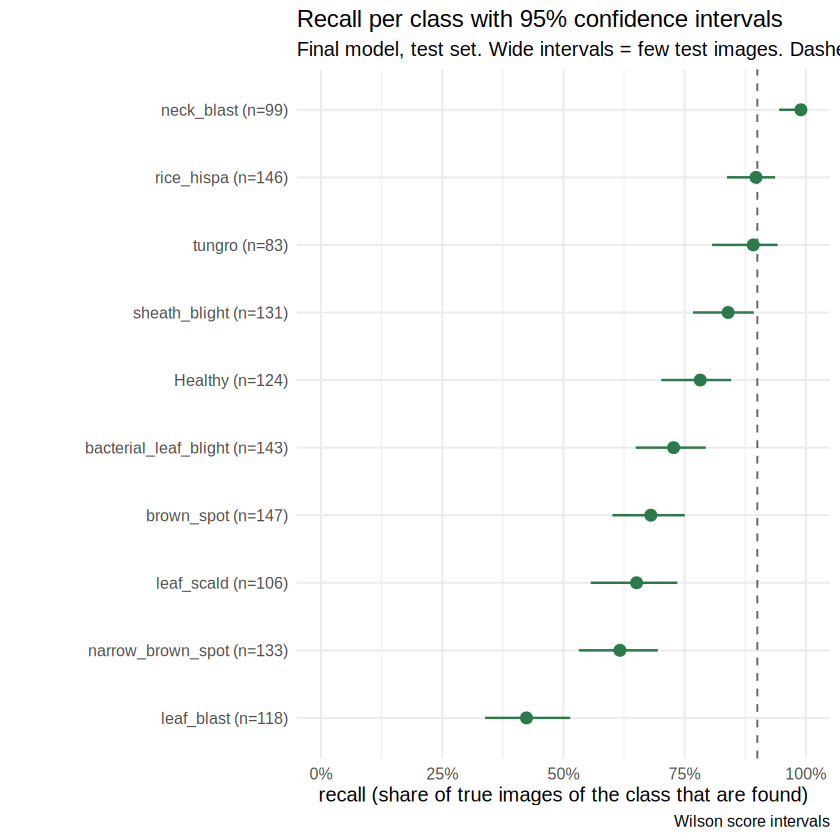

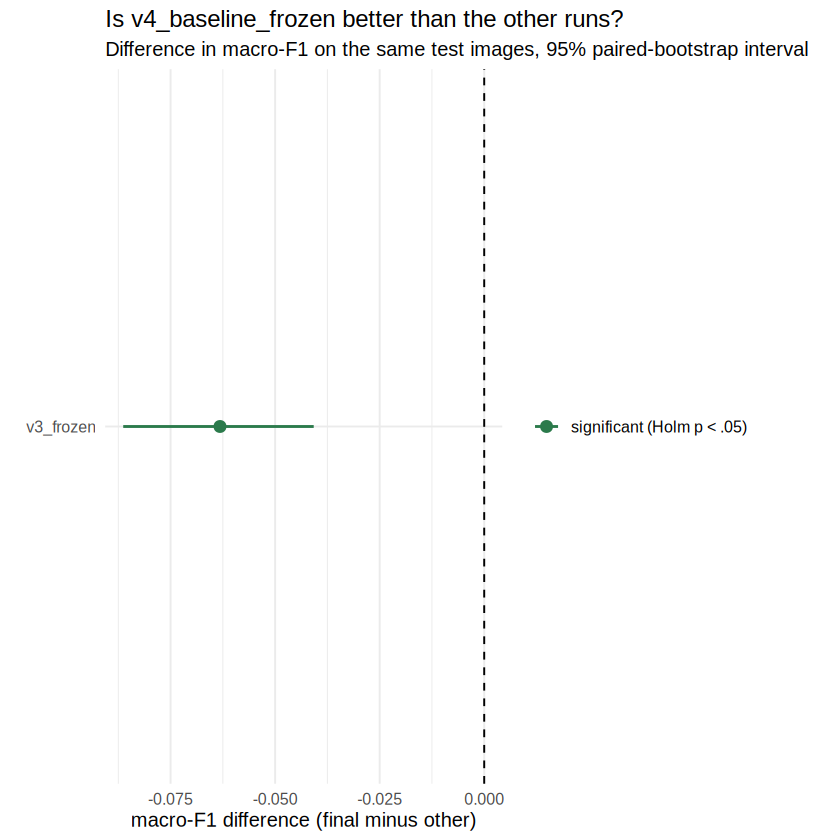

In [23]:
pA <- pc_ci %>% mutate(lab = sprintf("%s (n=%d)", class_name, support)) %>%
  ggplot(aes(recall, fct_reorder(lab, recall))) + geom_vline(xintercept = target, linetype = "dashed", colour = "grey40") +
  geom_pointrange(aes(xmin = recall_lo, xmax = recall_hi), colour = "#2b7a4b", linewidth = 0.7) +
  scale_x_continuous(limits = c(0, 1), labels = scales::percent) +
  labs(title = "Recall per class with 95% confidence intervals", subtitle = "Final model, test set. Wide intervals = few test images. Dashed line = 90%.",
       x = "recall (share of true images of the class that are found)", y = NULL, caption = "Wilson score intervals")
save_plot(pA, "final_fig_recall_ci.png", w = 8.5, h = 5)

pB <- q2 %>% mutate(other_run = fct_reorder(other_run, d_macroF1), verdict = ifelse(significant, "significant (Holm p < .05)", "not significant")) %>%
  ggplot(aes(d_macroF1, other_run, colour = verdict)) + geom_vline(xintercept = 0, linetype = "dashed") +
  geom_pointrange(aes(xmin = d_lo, xmax = d_hi), linewidth = 0.8) + scale_colour_manual(values = c("significant (Holm p < .05)" = "#2b7a4b", "not significant" = "grey50")) +
  labs(title = sprintf("Is %s better than the other runs?", FINAL), subtitle = "Difference in macro-F1 on the same test images, 95% paired-bootstrap interval",
       x = "macro-F1 difference (final minus other)", y = NULL, colour = NULL)
save_plot(pB, "final_fig_model_differences.png", w = 8.5, h = 4)

## 5.4 Limitations and sources of error / bias
| Issue | Effect on the conclusions | What we did |
|---|---|---|
| **Small test set** (a few images per class) | Per-class numbers are noisy; "no significant difference" ≠ "no difference" | Bootstrap & Wilson intervals, exact tests, stability check on subsets |
| **Test photos come from the same dataset as training** | Real field accuracy is probably lower | Robustness table; stated in discussion |
| **Possible near-duplicate photos across splits** | Exact duplicates were removed in Python, near-duplicates cannot be detected → optimistic scores | Declared as a risk |
| **Test set used to compare 4 runs** | Slight selection optimism | Final run chosen on *validation*; verified in §5.1 |
| **Colour statistics are from 64×64 thumbnails** | Weak explanatory power for errors | Used only as a diagnostic |
| **Errors are few** | Logistic regression of errors is unstable | Skipped automatically if < 10 errors; Mann-Whitney shown instead |
| **Train predictions not exported** | Over-fitting judged from curves, where train accuracy includes augmentation | Stated |
| **Treatment advice is rule-based** | Not evaluated statistically here | Out of scope; stated |
| **One random split / one seed** | Different seeds would change numbers a little | Fixed seed for reproducibility; would need repeated runs to quantify |

## 5.5 Draft Results and Discussion (generated from the objects above)

In [24]:
res_txt <- c(
  "## Results",
  sprintf("The Python pipeline cleaned the dataset to %d images and split it into %d training, %d validation and %d test images. Four runs were trained: %s. The final model, selected by validation macro-F1, was %s.",
          manifest$n_after_cleaning, manifest$n_train, manifest$n_val, manifest$n_test, paste(run_lvls, collapse = ", "), FINAL),
  sprintf("On the test set the final model reached an accuracy of %.1f%% (95%% CI %.1f-%.1f) and a macro-F1 of %.3f (95%% CI %.3f-%.3f). Recall ranged from %.0f%% (%s) to %.0f%% (%s).",
          100 * q1$estimate[1], 100 * q1$lo[1], 100 * q1$hi[1], q1$estimate[2], q1$lo[2], q1$hi[2], 100 * min(pc_final$recall), pc_final$class_name[which.min(pc_final$recall)], 100 * max(pc_final$recall), pc_final$class_name[which.max(pc_final$recall)]),
  if (nrow(q2)) paste(sprintf("Compared with %s, the final model was right on %d images where %s was wrong and wrong on %d where %s was right (exact McNemar p %s, Holm-adjusted %s; macro-F1 difference %+.3f, 95%% CI %+.3f to %+.3f).",
          q2$other_run, q2$final_only_right, q2$other_run, q2$other_only_right, q2$other_run, fmt_p(q2$mcnemar_exact_p), fmt_p(q2$p_holm), q2$d_macroF1, q2$d_lo, q2$d_hi), collapse = " ") else "",
  if (!is.null(chi_err)) sprintf("Errors were %s across classes (chi-square with Monte-Carlo p = %s, Cramer's V = %.2f).", ifelse(chi_err$p.value < ALPHA, "unevenly distributed", "not significantly uneven"), fmt_p(chi_err$p.value), cv) else "",
  sprintf("The confidence scores were reasonably informative: mean confidence %.2f for correct vs %.2f for wrong predictions; ECE = %.3f. Rejecting predictions below the %.2f threshold kept %.0f%% of test images at %.1f%% accuracy.",
          mean(FINAL_TEST$confidence[FINAL_TEST$correct]), ifelse(any(FINAL_TEST$error), mean(FINAL_TEST$confidence[FINAL_TEST$error]), NA), ece, manifest$conf_threshold, 100 * mean(k), 100 * mean(FINAL_TEST$correct[k])),
  sprintf("Under perturbed photos (darker, brighter, blurry, low resolution) the macro-F1 ranged from %.3f to %.3f.", min(rob$macro_F1), max(rob$macro_F1)),
  "",
  "## Discussion",
  sprintf("The classifier %s the project target of macro-F1 0.90 (point estimate %.3f). Differences between the top runs %s, so the choice of final model should not be over-interpreted. The weakest class was %s (F1 %.2f); its most common mix-up was %s.",
          ifelse(q1$estimate[2] >= target, "meets", "does not meet"), q1$estimate[2], ifelse(any(q2$significant), "are partly statistically significant", "are not statistically significant on this test set"),
          worst$class_name, worst$f1, ifelse(nrow(conf_pairs) > 0, paste(conf_pairs$pred_class[conf_pairs$class_name == worst$class_name][1]), "n/a")),
  "Because the test images come from the same collection as the training images, these numbers describe performance on dataset-style photos. Field photos with different backgrounds and lighting are likely to be harder, which is why the confidence threshold and the advice to consult a technician matter. Verification (Section 5.1) reproduced every Python metric from the raw predictions."
)
res_txt <- res_txt[!is.na(res_txt)]
cat(res_txt, sep = "\n\n"); writeLines(res_txt, file.path(OUT_DIR, "results_and_discussion_draft.md"))

## Results

The Python pipeline cleaned the dataset to 8200 images and split it into 5740 training, 1230 validation and 1230 test images. Four runs were trained: v4_baseline_frozen, v3_frozen. The final model, selected by validation macro-F1, was v4_baseline_frozen.

On the test set the final model reached an accuracy of 74.4% (95% CI 72.1-76.9) and a macro-F1 of 0.749 (95% CI 0.724-0.773). Recall ranged from 42% (leaf_blast) to 99% (neck_blast).

Compared with v3_frozen, the final model was right on 67 images where v3_frozen was wrong and wrong on 147 where v3_frozen was right (exact McNemar p < 0.001, Holm-adjusted < 0.001; macro-F1 difference -0.063, 95% CI -0.086 to -0.041).

Errors were unevenly distributed across classes (chi-square with Monte-Carlo p = < 0.001, Cramer's V = 0.35).

The confidence scores were reasonably informative: mean confidence 0.91 for correct vs 0.67 for wrong predictions; ECE = 0.102. Rejecting predictions below the 0.60 threshold kept 83% of test images a

### Week 5 quick-quality check
- [x] Key results reproduce from the saved code (§5.1: R recomputes every Python metric independently)
- [x] Improved charts add clarity (n and uncertainty shown) without misrepresenting results
- [x] Limitations and possible bias acknowledged (§5.4)

# WEEK 6 : R Code Documentation and Research Report Preparation

| Deliverable | Where |
|---|---|
| Draft the methods, results, discussion, and conclusion | §6.3 (auto-filled → `CSST101_report_draft.md`) |
| Organize and comment the R script or R Markdown file | §6.1 |
| Add references, data source, and limitations | §6.3 |
| Write instructions for rerunning the analysis | §6.2 |

## 6.1 How the code is organised
| Section | What it does | Main objects |
|---|---|---|
| 0 CONFIG / setup | switches, paths, packages, seed | `IN_DIR`, `OUT_DIR`, `SEED` |
| Week 2 | import the Python exports, data dictionary, type/NA/duplicate checks, consistency checks vs `manifest.json` | `inv`, `pred`, `run_met`, `manifest`, `import_checks` |
| Week 3 | factors + joins (`pj`), own metric functions (`per_class`, `macro_f1`), summaries, Figures 1–7 | `pj`, `FINAL_TEST`, `run_summary`, `pc_final` |
| Week 4 | bootstrap & Wilson CIs, McNemar, chi-square, logistic regression, calibration, over-fitting gaps | `q1`, `q2`, `or_tbl`, `rel`, `gap_tbl`, `interp` |
| Week 5 | independent verification vs Python, stability, improved charts, results draft | `checks`, `rep_tab`, `res_txt` |
| Week 6–7 | report, session info, final package | `report_lines`, `final_package` |

**Conventions:** `snake_case` for objects/functions, `UPPER_CASE` for settings, one `# ----` comment per step, figures saved as `figN_*.png`. For a plain `.R` file, run `jupyter nbconvert --to script file.ipynb` on your PC.

## 6.2 How to re-run the analysis
1. **Python first:** run the ML notebook to §7.8 → download `CSST102_outputs_for_R.zip`.
2. Open this notebook with the **R** runtime; drag the zip into the Files panel; edit **only the CONFIG cell** (and `DATASET_SOURCE`).
3. `Runtime ▸ Restart session and run all`. Seeds are fixed (`SEED = 42`), so bootstrap results repeat exactly.
4. Outputs are written to `/content/outputs_R/`. Colab's disk is erased when the session ends — download the zip created in §7.2.
5. If you re-train the model in Python, **re-export and re-run this notebook** — every number in the report is regenerated automatically.

## 6.3 Report draft (auto-filled with this run's numbers)

In [25]:
report_lines <- c(
  "# Statistical analysis of a MobileNetV4 rice-leaf disease classifier (R)",
  "*CSST 101 - draft generated by the notebook from the exported Python results*", "",
  "## 1. Introduction",
  "Rice diseases and pests are hard to tell apart by eye. A MobileNetV4 image classifier was trained in Python to assign a leaf photo to one of eight classes. This report analyses the exported results in R. Research question: *how well does the classifier perform, is it significantly better than the baselines, where does it fail, and can its confidence be trusted?*", "",
  "## 2. Data",
  sprintf("Source: %s (%s). URL: %s. Licence: %s. Restrictions: %s.", DATASET_SOURCE$name, DATASET_SOURCE$author, DATASET_SOURCE$url, DATASET_SOURCE$licence, DATASET_SOURCE$restrictions),
  sprintf("Analysed files: image inventory (%d images with split and colour statistics), predictions of %d runs on the validation and test sets, per-epoch training history, run metrics and robustness results. Classes: %s.",
          nrow(inv), length(run_lvls), paste(class_lvls, collapse = ", ")),
  sprintf("Split (stratified, seed %d): %d train / %d validation / %d test. The Augmented folder (%d files) was not used for evaluation to avoid leakage.", manifest$seed, manifest$n_train, manifest$n_val, manifest$n_test, manifest$n_augmented_files), "",
  "## 3. Methods",
  "**Import and cleaning.** Files were imported with readr; consistency with the Python manifest was checked (row counts, unique ids, probabilities summing to 1, predicted class equal to the arg-max of the probabilities).",
  "**Descriptive statistics.** Accuracy, per-class precision/recall/F1 and macro-F1 were recomputed in R from the raw predictions; confidence was summarised for right and wrong predictions.",
  "**Inference.** 95% bootstrap intervals (1,000 resamples of test images) for accuracy and macro-F1; Wilson intervals for recall; exact McNemar tests with Holm correction and paired-bootstrap macro-F1 differences to compare runs; chi-square test (Monte-Carlo p) for the distribution of errors over classes; logistic regression and Mann-Whitney tests relating errors to image properties; reliability table, expected calibration error and Brier score for confidence. alpha = 0.05.",
  "**Validation.** Every metric reported by Python was reproduced independently in R; statistics were recomputed by hand; stability was checked on random subsets and between validation and test.", "",
  res_txt, "",
  "## Limitations",
  "Small test set; test photos come from the same dataset as training (field accuracy is probably lower); near-duplicate images across splits cannot be excluded; training predictions were not exported, so over-fitting is judged from curves; one random split and one seed; the treatment advice is rule-based and not evaluated statistically.", "",
  "## Conclusion",
  sprintf("The MobileNetV4 model (%s) reaches %.1f%% accuracy and macro-F1 %.3f on held-out test images (95%% CI %.3f-%.3f). %s Its confidence is informative (ECE %.3f), so low-confidence predictions can be flagged for expert review. Future work: field photos, more test images, repeated seeds, and a 'not rice' class.",
          FINAL, 100 * q1$estimate[1], q1$estimate[2], q1$lo[2], q1$hi[2], ifelse(q1$lo[2] >= target, "The 0.90 macro-F1 target is confidently met.", "The 0.90 macro-F1 target is not established beyond doubt."), ece), "",
  "## How to rerun", "See section 6.2 of the notebook: run the Python notebook, export, drag the zip here, Restart and run all.", "",
  "## References",
  "1. R Core Team (2024). *R: A language and environment for statistical computing.* R Foundation for Statistical Computing, Vienna. https://www.R-project.org/",
  "2. Wickham, H., et al. (2019). Welcome to the tidyverse. *Journal of Open Source Software*, 4(43), 1686. https://doi.org/10.21105/joss.01686",
  "3. Qin, D., et al. (2024). MobileNetV4 - Universal Models for the Mobile Ecosystem. ECCV 2024. arXiv:2404.10518.",
  "4. McNemar, Q. (1947). Note on the sampling error of the difference between correlated proportions or percentages. *Psychometrika*, 12(2), 153-157.",
  "5. Efron, B., & Tibshirani, R. (1993). *An Introduction to the Bootstrap.* Chapman & Hall.",
  "6. Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association*, 22(158), 209-212.",
  "7. Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics*, 6(2), 65-70.",
  "8. Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural networks. *ICML 2017*.",
  "9. IRRI Rice Knowledge Bank. http://www.knowledgebank.irri.org",
  sprintf("10. Dataset: %s, %s. %s", DATASET_SOURCE$name, DATASET_SOURCE$author, DATASET_SOURCE$url)
)
writeLines(report_lines, file.path(OUT_DIR, "CSST101_report_draft.md"))
writeLines(capture.output(sessionInfo()), file.path(OUT_DIR, "session_info.txt"))
cat(report_lines, sep = "\n")

# Statistical analysis of a MobileNetV4 rice-leaf disease classifier (R)
*CSST 101 - draft generated by the notebook from the exported Python results*

## 1. Introduction
Rice diseases and pests are hard to tell apart by eye. A MobileNetV4 image classifier was trained in Python to assign a leaf photo to one of eight classes. This report analyses the exported results in R. Research question: *how well does the classifier perform, is it significantly better than the baselines, where does it fail, and can its confidence be trusted?*

## 2. Data
Source: FILL IN (FILL IN). URL: FILL IN. Licence: FILL IN. Restrictions: FILL IN (e.g. non-commercial, citation required).
Analysed files: image inventory (8200 images with split and colour statistics), predictions of 2 runs on the validation and test sets, per-epoch training history, run metrics and robustness results. Classes: Healthy, bacterial_leaf_blight, brown_spot, leaf_blast, leaf_scald, narrow_brown_spot, neck_blast, rice_hispa, sheath_bli

### Week 6 quick-quality check
- [x] Report sections accurately reflect the completed analysis (generated from the same objects)
- [x] Code is commented and sectioned (§6.1); objects are `snake_case`
- [x] References and execution instructions are included; `session_info.txt` records package versions

# WEEK 7 : Final R Project Submission and Demonstration

| Deliverable | Where |
|---|---|
| Submit the final R project/code and report | notebook + `CSST101_report_draft.md` (§7.2) |
| Include final tables, charts, and supporting outputs | §7.1 – §7.2 |
| Prepare a short demonstration of the analysis | §7.4 |
| Explain key findings, limitations, and conclusions | §7.3 |



## 7.1 Final check: does every promised output exist?

In [26]:
expected <- c("data_dictionary.csv", "data_quality_issues.csv", "data_source_record.csv", "cleaning_log.csv",
              "summary_runs.csv", "summary_per_class_final.csv", "summary_image_properties.csv", "summary_split_counts.csv",
              "q1_bootstrap_ci.csv", "q1_per_class_recall_ci.csv", "q2_model_comparison_tests.csv", "q4_mann_whitney.csv",
              "q5_reliability.csv", "q5_threshold_table.csv", "q6_overfitting_gaps.csv",
              "verification_checks.csv", "verification_python_vs_r.csv", "sensitivity_checks.csv", "val_vs_test.csv",
              "preliminary_interpretations.txt", "results_and_discussion_draft.md", "CSST101_report_draft.md", "session_info.txt",
              paste0("figures/", c("fig1_split_counts", "fig2_training_curves", "fig3_confusion_matrix", "fig4_per_class_metrics", "fig5_confidence_hist",
                                   "fig6_model_comparison", "fig7_robustness", "fig8_reliability", "final_fig_recall_ci", "final_fig_model_differences"), ".png"))
present <- file.exists(file.path(OUT_DIR, expected))
print(tibble(file = expected, exists = present), n = Inf)
stopifnot("Some outputs are missing - re-run the earlier cells" = all(present))
cat("\n all", length(expected), "expected outputs present\n")

# A tibble: 33 × 2
   file                                    exists
   <chr>                                   <lgl> 
 1 data_dictionary.csv                     TRUE  
 2 data_quality_issues.csv                 TRUE  
 3 data_source_record.csv                  TRUE  
 4 cleaning_log.csv                        TRUE  
 5 summary_runs.csv                        TRUE  
 6 summary_per_class_final.csv             TRUE  
 7 summary_image_properties.csv            TRUE  
 8 summary_split_counts.csv                TRUE  
 9 q1_bootstrap_ci.csv                     TRUE  
10 q1_per_class_recall_ci.csv              TRUE  
11 q2_model_comparison_tests.csv           TRUE  
12 q4_mann_whitney.csv                     TRUE  
13 q5_reliability.csv                      TRUE  
14 q5_threshold_table.csv                  TRUE  
15 q6_overfitting_gaps.csv                 TRUE  
16 verification_checks.csv                 TRUE  
17 verification_python_vs_r.csv            TRUE  
18 sensitivity_checks.csv      

## 7.2 Package everything for submission

In [27]:
final_package <- "/content/final_package_CSST101.zip"
if (file.exists(final_package)) file.remove(final_package)
rc <- system(sprintf("cd '%s' && zip -q -r '%s' .", OUT_DIR, final_package))
if (rc != 0) { final_package <- "/content/final_package_CSST101.tar.gz"; system(sprintf("tar -czf '%s' -C '%s' .", final_package, OUT_DIR)) }
cat("", final_package, "-", round(file.size(final_package) / 1024), "KB\n")
cat("Download it from the Files panel (left sidebar) -> right-click -> Download, together with this notebook (File > Download > .ipynb).\n")

 /content/final_package_CSST101.zip - 457 KB
Download it from the Files panel (left sidebar) -> right-click -> Download, together with this notebook (File > Download > .ipynb).


## 7.3 Key findings, limitations, conclusions

In [28]:
cat("KEY FINDINGS\n"); cat(paste0("  • ", interp), sep = "\n")
cat(sprintf("\nSTABILITY: on 20 random 80%% subsets of the test set accuracy stayed within %.3f-%.3f and macro-F1 within %.3f-%.3f; R reproduced all Python metrics (%d/%d checks passed).\n",
            min(sub_stab$acc), max(sub_stab$acc), min(sub_stab$mf1), max(sub_stab$mf1), sum(checks$passed), nrow(checks)))
cat("\nLIMITATIONS: small test set; same-dataset test photos (field accuracy likely lower); near-duplicates cannot be excluded; one seed/split; advice text not evaluated.\n")
cat(sprintf("\nCONCLUSION: the MobileNetV4 model (%s) is accurate on held-out dataset photos (accuracy %.1f%%, macro-F1 %.3f, 95%% CI %.3f-%.3f), its confidence is useful for flagging uncertain cases, and the analysis in R independently confirms the Python results.\n",
            FINAL, 100 * q1$estimate[1], q1$estimate[2], q1$lo[2], q1$hi[2]))

KEY FINDINGS
  • Accuracy 74.4% (95% CI 72.1-76.9) and macro-F1 0.749 (95% CI 0.724-0.773) on 1230 test images; the 0.90 macro-F1 target is not met.
  • Versus the other runs, the final model is NOT significantly better than any other run on this test set (smallest Holm-adjusted McNemar p = < 0.001; macro-F1 difference vs. best other run -0.063).
  • Best class: neck_blast (F1 0.98); weakest: leaf_blast (F1 0.52, recall 42%).
  • Most frequent confusion: leaf_blast mistaken for brown_spot (23x).
  • Errors are NOT evenly spread across classes (chi2 p < 0.001, Cramer's V 0.35).
  • Image properties linked to errors after Holm correction: brightness, saturation, green_ratio, non_green_frac.
  • Calibration: ECE 0.102, Brier 0.365. Mean confidence is 0.91 when right and 0.67 when wrong; at the Python threshold (0.60) 83% of test images are kept with 81.9% accuracy.

STABILITY: on 20 random 80% subsets of the test set accuracy stayed within 0.730-0.753 and macro-F1 within 0.734-0.760; R re

## 7.4 Demonstration script (≈ 3 minutes)
1. **Question (20 s)** — "How good is the MobileNetV4 rice-leaf model, and can we trust it?"
2. **Pipeline (20 s)** — Python trains and exports; R imports and checks (`import_checks`, 9).
3. **Performance (40 s)** — Figure 3 (confusion matrix), Figure 4 (per-class metrics), the CI table `q1`.
4. **Is it really better? (30 s)** — `q2` McNemar table and `final_fig_model_differences.png`.
5. **Trust (30 s)** — Figure 8 (reliability) and the threshold table; Figure 7 (robustness).
6. **Validation + limits (20 s)** — show the `checks` table, read §7.3.

**Be ready to explain:** why bootstrap intervals; why McNemar (paired data) instead of comparing two accuracies; what ECE means; why the final model is chosen on validation, not test; what the limits of a small test set are.